# SQLite и 12 аналитических SQL запросов
Zhenissov Kaiyrbek и Bekarys. Нормализация, JOIN, CTE, HAVING, оконные функции и чтение в Pandas. Целевые связи ограничены fit.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'src').exists(): ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
from src.config import *
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 60)
def table(name): return pd.read_csv(TABLES / name)
def figure(name, width=1000): display(Image(filename=str(FIGURES / name), width=width))


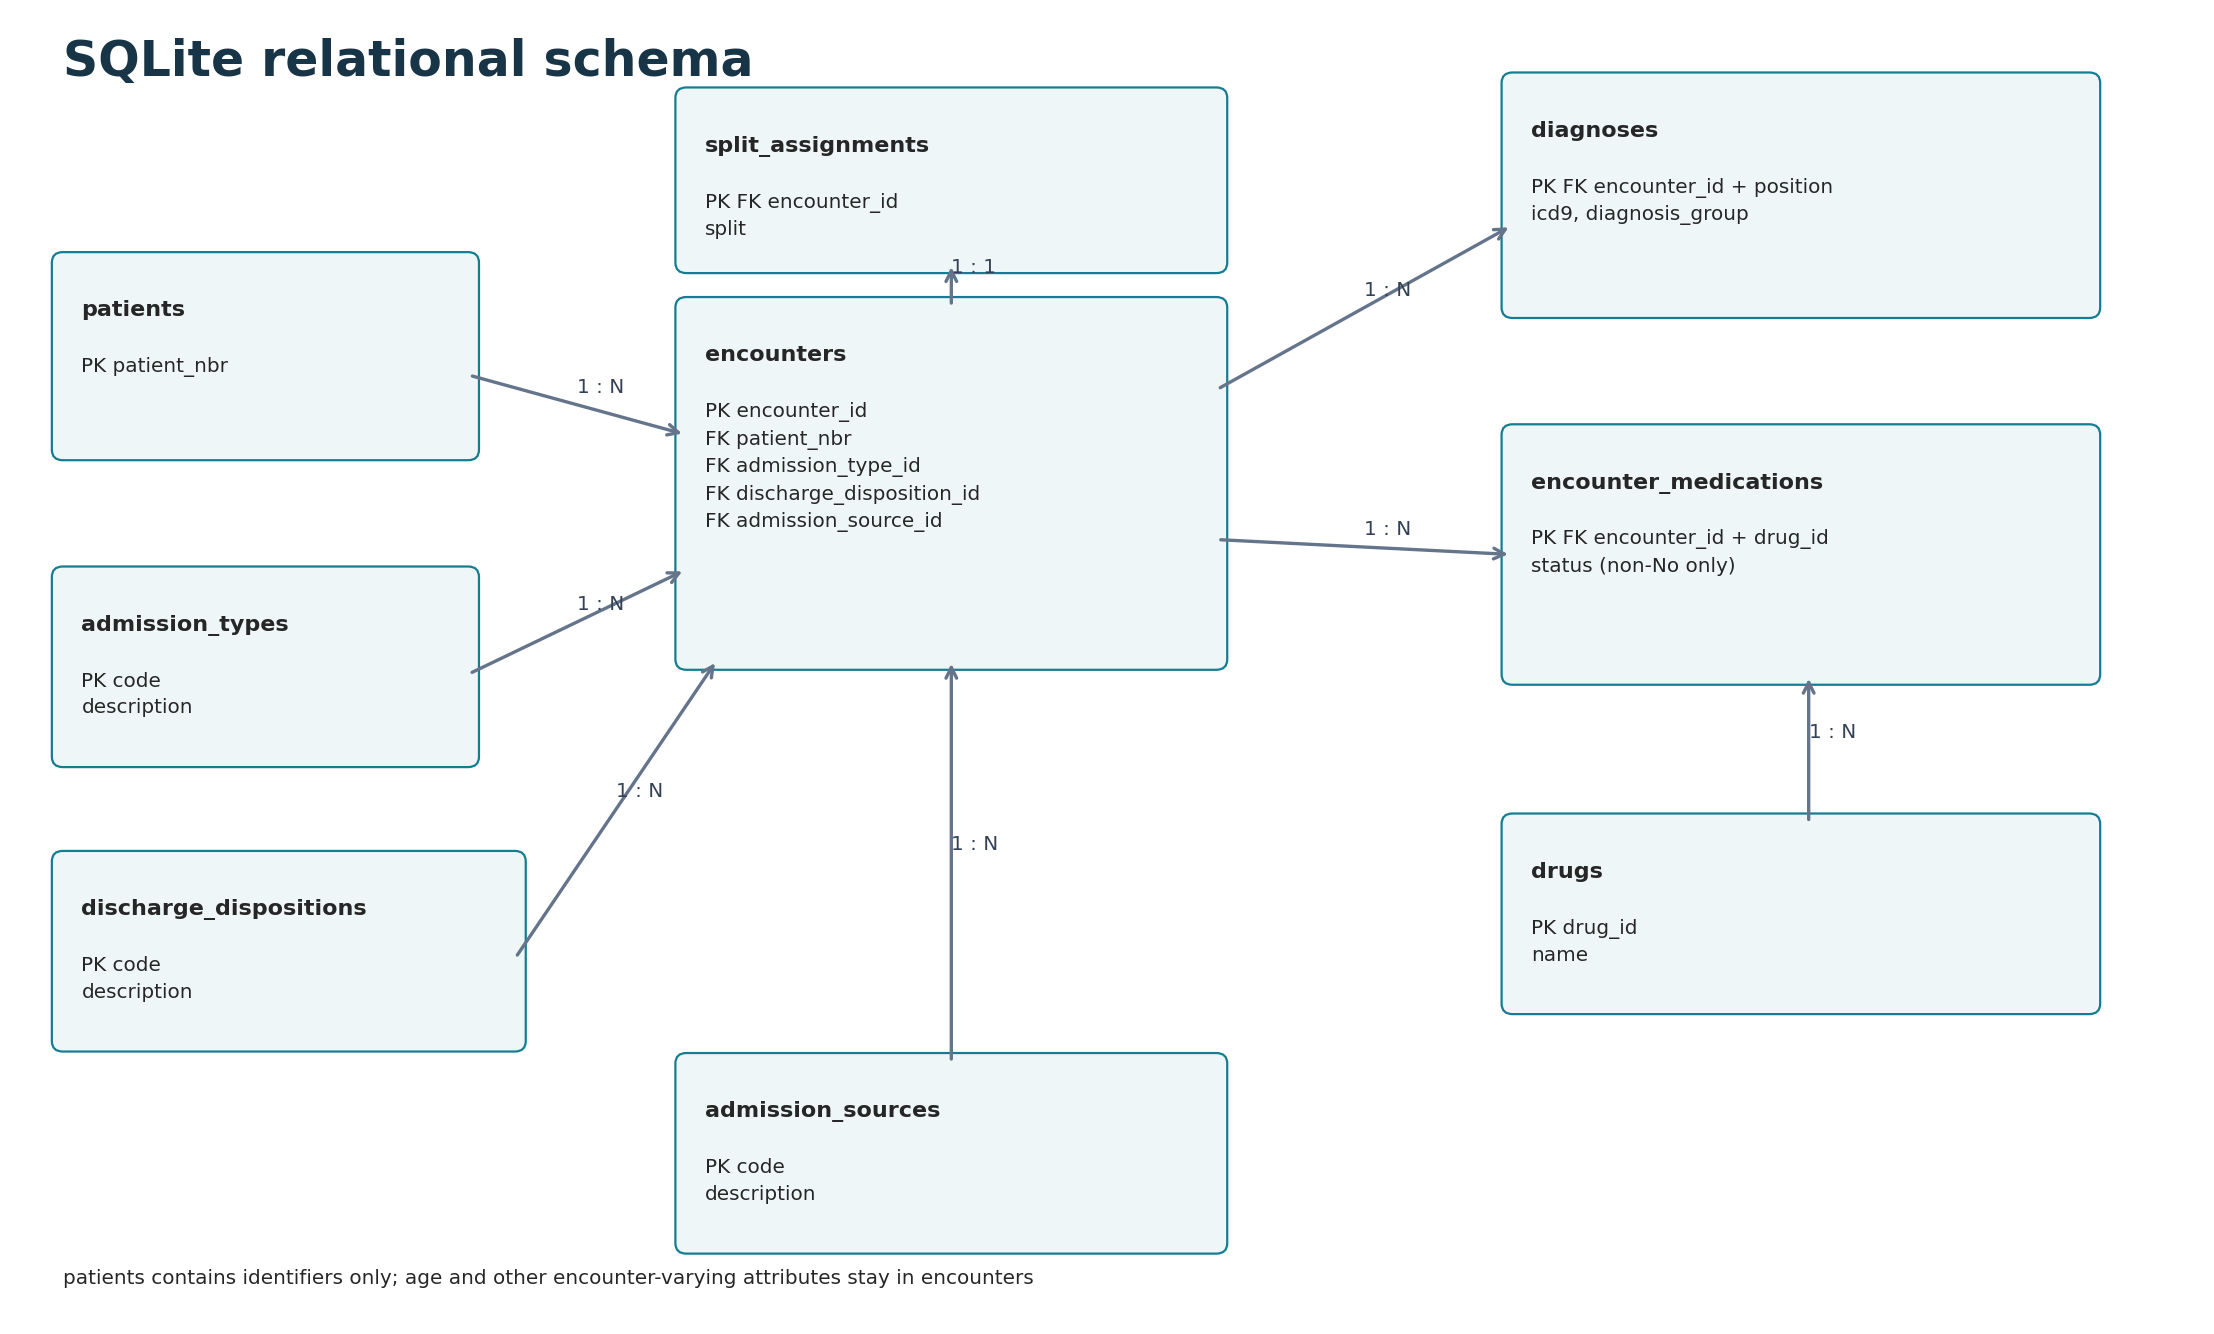

In [2]:
figure('er_diagram.png')

In [3]:
from contextlib import closing
from src.database import connect, load_sql_queries
with closing(connect()) as connection:
    for name,query in load_sql_queries().items():
        display(Markdown('## '+name+'\n```sql\n'+query+'\n```'))
        result=pd.read_sql_query(query,connection)
        print('Rows:',len(result))
        display(result.head(25))
    print('Foreign key violations:',connection.execute('PRAGMA foreign_key_check').fetchall())

## 01_class_balance
```sql
SELECT readmitted, COUNT(*) AS encounters,
       ROUND(100.0*COUNT(*)/SUM(COUNT(*)) OVER (),2) AS share_pct
FROM encounters GROUP BY readmitted
```

Rows: 3


,readmitted,encounters,share_pct
0,<30,11357,11.16
1,>30,35545,34.93
2,NO,54864,53.91


## 02_patient_recurrence
```sql
SELECT patient_nbr, COUNT(*) AS encounters, SUM(readmitted_30d) AS early_readmissions
FROM encounters GROUP BY patient_nbr HAVING COUNT(*) > 1
ORDER BY encounters DESC, patient_nbr LIMIT 20
```

Rows: 20


,patient_nbr,encounters,early_readmissions
0,88785891,40,23
1,43140906,28,22
2,1660293,23,11
3,23199021,23,7
4,88227540,23,12
5,23643405,22,12
6,84428613,22,12
7,92709351,21,12
8,23398488,20,12
9,29903877,20,7


... (27 outputs left out)

## 12_specialty_window
```sql
WITH counts AS (
 SELECT COALESCE(medical_specialty,'Missing') AS specialty,COUNT(*) AS encounters
 FROM encounters GROUP BY COALESCE(medical_specialty,'Missing')
)
SELECT *,ROUND(100.0*SUM(encounters) OVER(ORDER BY encounters DESC,specialty
 ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)/SUM(encounters) OVER(),2) AS cumulative_pct
FROM counts ORDER BY encounters DESC,specialty
```

Rows: 73


,specialty,encounters,cumulative_pct
0,Missing,49949,49.08
1,InternalMedicine,14635,63.46
2,Emergency/Trauma,7565,70.90
3,Family/GeneralPractice,7440,78.21
4,Cardiology,5352,83.47
5,Surgery-General,3099,86.51
6,Nephrology,1613,88.10
7,Orthopedics,1400,89.47
8,Orthopedics-Reconstructive,1233,90.68
9,Radiologist,1140,91.80


Foreign key violations: []


Запрос 09 должен вернуть ноль строк. В encounter_medications хранятся только состояния не-No; отсутствие назначения означает No. Нормализация не создаёт дополнительных независимых госпитализаций.